# Exercise B — Classification

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

np.random.seed(42)

## B.I.1 — Dataset 1

We create a binary classification dataset with 2 features (x1, x2).

- Class 0: 40 points around (-1.5, -1.0)
- Class 1: 40 points around (1.5, 1.0)

`np.random.randn` gives random values from a normal distribution.
We multiply by 0.7 to control the spread, then add the center.

In [2]:
# Class 0: 40 points around (-1.5, -1.0)
X0 = np.random.randn(40, 2) * 0.7 + np.array([-1.5, -1.0])
y0 = np.zeros(40)

# Class 1: 40 points around (1.5, 1.0)
X1 = np.random.randn(40, 2) * 0.7 + np.array([1.5, 1.0])
y1 = np.ones(40)

# Put both classes together
X_dataset1 = np.vstack([X0, X1])
y_dataset1 = np.concatenate([y0, y1])

print("Shape of X_dataset1:", X_dataset1.shape)
print("Shape of y_dataset1:", y_dataset1.shape)
print()
print("All Dataset 1 points (x1, x2, class):")
print(np.column_stack([X_dataset1, y_dataset1]))

Shape of X_dataset1: (80, 2)
Shape of y_dataset1: (80,)

All Dataset 1 points (x1, x2, class):
[[-1.15230009 -1.09678501  0.        ]
 [-1.04661802  0.0661209   0.        ]
 [-1.66390736 -1.16389587  0.        ]
 [-0.39455103 -0.46279569  0.        ]
 [-1.82863207 -0.62020797  0.        ]
 [-1.82439238 -1.32601083  0.        ]
 [-1.33062641 -2.33929617  0.        ]
 [-2.70744248 -1.39360127  0.        ]
 [-2.20898178 -0.78002687  0.        ]
 [-2.13561685 -1.98861259  0.        ]
 [-0.47404586 -1.15804341  0.        ]
 [-1.45273026 -1.99732373  0.        ]
 [-1.88106791 -0.92235419  0.        ]
 [-2.3056955  -0.73701139  0.        ]
 [-1.92044708 -1.20418562  0.        ]
 [-1.92119463  0.29659473  0.        ]
 [-1.50944806 -1.74039765  0.        ]
 [-0.92421856 -1.85459055  0.        ]
 [-1.35379548 -2.37176909  0.        ]
 [-2.42973023 -0.86219713  0.        ]
 [-0.98307339 -0.8800422   0.        ]
 [-1.5809538  -1.21077259  0.        ]
 [-2.53496539 -1.50389095  0.        ]
 [-1.822

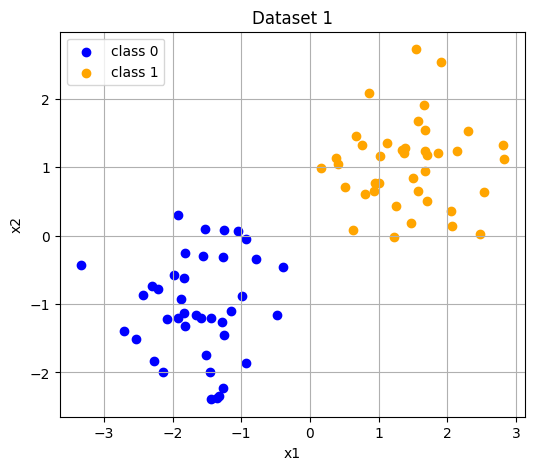

In [3]:
plt.figure(figsize=(6, 5))
plt.scatter(X0[:, 0], X0[:, 1], color="blue", label="class 0")
plt.scatter(X1[:, 0], X1[:, 1], color="orange", label="class 1")
plt.title("Dataset 1")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.show()

## B.I.2 — Dataset 2 (Dataset 1 + outliers)

We add 4 outliers for each class.
Outliers are points that are far away, in the region of the other class.

In [4]:
# 4 outliers for class 0 (placed near class 1)
outliers_class0 = np.array([
    [3.5, 3.0],
    [3.0, 2.5],
    [2.8, 3.5],
    [3.8, 2.2],
])

# 4 outliers for class 1 (placed near class 0)
outliers_class1 = np.array([
    [-3.5, -3.0],
    [-3.0, -2.5],
    [-2.8, -3.5],
    [-3.8, -2.2],
])

# Dataset 2 = Dataset 1 + outliers
X_dataset2 = np.vstack([X_dataset1, outliers_class0, outliers_class1])
y_dataset2 = np.concatenate([y_dataset1, np.zeros(4), np.ones(4)])

print("Shape of X_dataset2:", X_dataset2.shape)
print("Shape of y_dataset2:", y_dataset2.shape)
print()
print("Outliers class 0:")
print(outliers_class0)
print()
print("Outliers class 1:")
print(outliers_class1)
print()
print("All Dataset 2 points (x1, x2, class):")
print(np.column_stack([X_dataset2, y_dataset2]))

Shape of X_dataset2: (88, 2)
Shape of y_dataset2: (88,)

Outliers class 0:
[[3.5 3. ]
 [3.  2.5]
 [2.8 3.5]
 [3.8 2.2]]

Outliers class 1:
[[-3.5 -3. ]
 [-3.  -2.5]
 [-2.8 -3.5]
 [-3.8 -2.2]]

All Dataset 2 points (x1, x2, class):
[[-1.15230009 -1.09678501  0.        ]
 [-1.04661802  0.0661209   0.        ]
 [-1.66390736 -1.16389587  0.        ]
 [-0.39455103 -0.46279569  0.        ]
 [-1.82863207 -0.62020797  0.        ]
 [-1.82439238 -1.32601083  0.        ]
 [-1.33062641 -2.33929617  0.        ]
 [-2.70744248 -1.39360127  0.        ]
 [-2.20898178 -0.78002687  0.        ]
 [-2.13561685 -1.98861259  0.        ]
 [-0.47404586 -1.15804341  0.        ]
 [-1.45273026 -1.99732373  0.        ]
 [-1.88106791 -0.92235419  0.        ]
 [-2.3056955  -0.73701139  0.        ]
 [-1.92044708 -1.20418562  0.        ]
 [-1.92119463  0.29659473  0.        ]
 [-1.50944806 -1.74039765  0.        ]
 [-0.92421856 -1.85459055  0.        ]
 [-1.35379548 -2.37176909  0.        ]
 [-2.42973023 -0.86219713  0

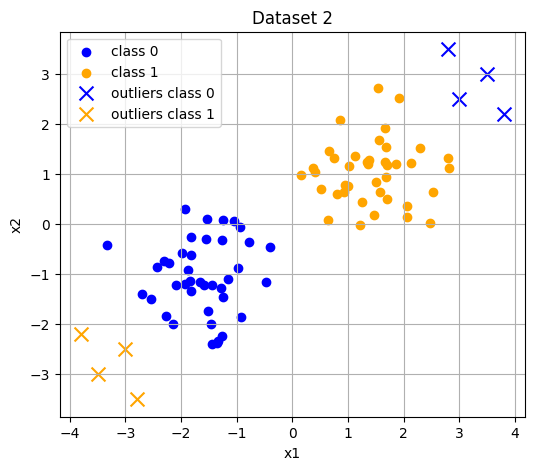

In [5]:
plt.figure(figsize=(6, 5))
plt.scatter(X0[:, 0], X0[:, 1], color="blue", label="class 0")
plt.scatter(X1[:, 0], X1[:, 1], color="orange", label="class 1")
plt.scatter(outliers_class0[:, 0], outliers_class0[:, 1],
            color="blue", marker="x", s=100, label="outliers class 0")
plt.scatter(outliers_class1[:, 0], outliers_class1[:, 1],
            color="orange", marker="x", s=100, label="outliers class 1")
plt.title("Dataset 2")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.show()

## B.I.3 — Train / test split

We split each dataset into:
- 70% training data
- 30% testing data

`stratify` keeps the same class balance in train and test.
`random_state=42` makes the split reproducible.

In [6]:
########## Dataset 1 split ##########
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X_dataset1, y_dataset1, test_size=0.3, random_state=42, stratify=y_dataset1
)

print("Dataset 1 train size:", len(y1_train))
print("Dataset 1 test size:", len(y1_test))
print()
print("Dataset 1 train (x1, x2, class):")
print(np.column_stack([X1_train, y1_train]))
print()
print("Dataset 1 test (x1, x2, class):")
print(np.column_stack([X1_test, y1_test]))

Dataset 1 train size: 56
Dataset 1 test size: 24

Dataset 1 train (x1, x2, class):
[[ 1.54216115  2.72426948  1.        ]
 [-1.9738454  -0.5718266   0.        ]
 [ 1.12916786  1.3592872   1.        ]
 [ 1.34622968  1.2499788   1.        ]
 [ 2.48195602  0.01870426  1.        ]
 [-2.3056955  -0.73701139  0.        ]
 [ 0.9517227   0.77455694  1.        ]
 [-1.88106791 -0.92235419  0.        ]
 [ 1.56795428  1.67805149  1.        ]
 [ 1.68028527  0.94788786  1.        ]
 [ 1.68191796  1.54727601  1.        ]
 [ 1.70515073  0.49995401  1.        ]
 [ 1.22552429 -0.02446046  1.        ]
 [-1.55040709 -0.29752697  0.        ]
 [ 0.37476174  1.1292437   1.        ]
 [-1.50944806 -1.74039765  0.        ]
 [-2.13561685 -1.98861259  0.        ]
 [-1.52507823  0.09525056  0.        ]
 [ 1.8653591   1.20788927  1.        ]
 [-1.45273026 -1.99732373  0.        ]
 [ 0.15686015  0.98144029  1.        ]
 [ 1.3871      1.2828356   1.        ]
 [-1.33062641 -2.33929617  0.        ]
 [-1.82863207 -0.620

In [7]:
########## Dataset 2 split ##########
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_dataset2, y_dataset2, test_size=0.3, random_state=42, stratify=y_dataset2
)

print("Dataset 2 train size:", len(y2_train))
print("Dataset 2 test size:", len(y2_test))
print()
print("Dataset 2 train (x1, x2, class):")
print(np.column_stack([X2_train, y2_train]))
print()
print("Dataset 2 test (x1, x2, class):")
print(np.column_stack([X2_test, y2_test]))

Dataset 2 train size: 61
Dataset 2 test size: 27

Dataset 2 train (x1, x2, class):
[[-1.92119463  0.29659473  0.        ]
 [-2.13561685 -1.98861259  0.        ]
 [-1.27314122 -1.2695576   0.        ]
 [ 3.          2.5         0.        ]
 [ 3.8         2.2         0.        ]
 [ 1.34622968  1.2499788   1.        ]
 [ 0.66608755  1.45958753  1.        ]
 [-1.2681156  -0.31711841  0.        ]
 [ 0.80662457  0.60359159  1.        ]
 [ 1.70515073  0.49995401  1.        ]
 [ 1.50357942  0.83578901  1.        ]
 [-0.93123192 -0.05063198  0.        ]
 [ 0.50924048  0.70554827  1.        ]
 [-0.39455103 -0.46279569  0.        ]
 [-1.50944806 -1.74039765  0.        ]
 [ 1.56795428  1.67805149  1.        ]
 [-3.33382157 -0.42466825  0.        ]
 [-2.42973023 -0.86219713  0.        ]
 [ 2.48195602  0.01870426  1.        ]
 [ 1.47570176  0.18192537  1.        ]
 [-1.04661802  0.0661209   0.        ]
 [-2.8        -3.5         1.        ]
 [-1.82439238 -1.32601083  0.        ]
 [-2.27443448 -1.837

## Helper functions

`plot_boundary` draws the decision regions of a trained model.
`evaluate` fits a model and prints accuracy + confusion matrix.

In [ ]:
def plot_boundary(model, X, y, title):
    """Plot the decision boundary of a trained classifier."""
    x_min = X[:, 0].min() - 1
    x_max = X[:, 0].max() + 1
    y_min = X[:, 1].min() - 1
    y_max = X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, 0.05),
        np.arange(y_min, y_max, 0.05),
    )

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.4, cmap=ListedColormap(["#FFAAAA", "#AAAAFF"]))
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="k",
                cmap=ListedColormap(["#FF0000", "#0000FF"]))
    plt.title(title)
    plt.xlabel("x1")
    plt.ylabel("x2")


def evaluate(name, model, X_train, y_train, X_test, y_test):
    """Train the model and print train plus test accuracy and confusion matrices."""
    model.fit(X_train, y_train)

    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    print(name)
    print("train accuracy:", accuracy_score(y_train, pred_train))
    print("test  accuracy:", accuracy_score(y_test, pred_test))
    print("confusion matrix train:")
    print(confusion_matrix(y_train, pred_train))
    print("confusion matrix test:")
    print(confusion_matrix(y_test, pred_test))
    print()

    return model

## B.I.4 — Train the classifiers

We use:
- **k-NN** with k=5
- **GaussianNB** (Naive Bayes for continuous features)
- **SVC** with RBF kernel and C=1 (as recommended in the assignment)

In [9]:
########## Dataset 1 ##########
print("========== Dataset 1 ==========")
print()

evaluate("k-NN (k=5)", KNeighborsClassifier(n_neighbors=5),
         X1_train, y1_train, X1_test, y1_test)

evaluate("GaussianNB", GaussianNB(),
         X1_train, y1_train, X1_test, y1_test)

evaluate("SVC (RBF, C=1)", SVC(kernel="rbf", C=1),
         X1_train, y1_train, X1_test, y1_test)

========== Dataset 1 ==========

k-NN (k=5)
  train accuracy: 1.0
  test  accuracy: 1.0
  confusion matrix train:
[[28  0]
 [ 0 28]]
  confusion matrix test:
[[12  0]
 [ 0 12]]

GaussianNB
  train accuracy: 1.0
  test  accuracy: 1.0
  confusion matrix train:
[[28  0]
 [ 0 28]]
  confusion matrix test:
[[12  0]
 [ 0 12]]

SVC (RBF, C=1)
  train accuracy: 1.0
  test  accuracy: 1.0
  confusion matrix train:
[[28  0]
 [ 0 28]]
  confusion matrix test:
[[12  0]
 [ 0 12]]



SVC(C=1)

In [10]:
########## Dataset 2 ##########
print("========== Dataset 2 ==========")
print()

evaluate("k-NN (k=5)", KNeighborsClassifier(n_neighbors=5),
         X2_train, y2_train, X2_test, y2_test)

evaluate("GaussianNB", GaussianNB(),
         X2_train, y2_train, X2_test, y2_test)

evaluate("SVC (RBF, C=1)", SVC(kernel="rbf", C=1),
         X2_train, y2_train, X2_test, y2_test)

========== Dataset 2 ==========

k-NN (k=5)
  train accuracy: 0.9672131147540983
  test  accuracy: 0.9259259259259259
  confusion matrix train:
[[30  0]
 [ 2 29]]
  confusion matrix test:
[[14  0]
 [ 2 11]]

GaussianNB
  train accuracy: 0.9180327868852459
  test  accuracy: 0.8888888888888888
  confusion matrix train:
[[27  3]
 [ 2 29]]
  confusion matrix test:
[[13  1]
 [ 2 11]]

SVC (RBF, C=1)
  train accuracy: 1.0
  test  accuracy: 1.0
  confusion matrix train:
[[30  0]
 [ 0 31]]
  confusion matrix test:
[[14  0]
 [ 0 13]]



SVC(C=1)

### Discussion B.I.4

On Dataset 1 the classes are well separated, so all models get very high accuracy.

On Dataset 2 the outliers make the problem harder. Accuracy drops for k-NN and Naive Bayes.
SVC with RBF can still fit the data well because its boundary is more flexible.

## B.I.5 — Different kernels and C for SVM

We try:
- kernels: linear, rbf, poly
- C values: 0.01, 0.1, 1, 10, 100

C is the regularization parameter:
- small C = more regularization (simpler boundary)
- large C = less regularization (more complex boundary)

In [11]:
########## Dataset 1 ##########
print("========== Dataset 1 ==========")

for kernel in ["linear", "rbf", "poly"]:
    for C in [0.01, 0.1, 1, 10, 100]:
        model = SVC(kernel=kernel, C=C)
        model.fit(X1_train, y1_train)

        train_acc = accuracy_score(y1_train, model.predict(X1_train))
        test_acc = accuracy_score(y1_test, model.predict(X1_test))

        print(f"  kernel={kernel:7s} C={C:6.2f}  train={train_acc:.3f}  test={test_acc:.3f}")

========== Dataset 1 ==========
  kernel=linear  C=  0.01  train=1.000  test=1.000
  kernel=linear  C=  0.10  train=1.000  test=1.000
  kernel=linear  C=  1.00  train=1.000  test=1.000
  kernel=linear  C= 10.00  train=1.000  test=1.000
  kernel=linear  C=100.00  train=1.000  test=1.000
  kernel=rbf     C=  0.01  train=1.000  test=1.000
  kernel=rbf     C=  0.10  train=1.000  test=1.000
  kernel=rbf     C=  1.00  train=1.000  test=1.000
  kernel=rbf     C= 10.00  train=1.000  test=1.000
  kernel=rbf     C=100.00  train=1.000  test=1.000
  kernel=poly    C=  0.01  train=0.875  test=0.792
  kernel=poly    C=  0.10  train=0.946  test=0.833
  kernel=poly    C=  1.00  train=0.964  test=0.833
  kernel=poly    C= 10.00  train=0.982  test=0.917
  kernel=poly    C=100.00  train=1.000  test=0.958


In [12]:
########## Dataset 2 ##########
print("========== Dataset 2 ==========")

for kernel in ["linear", "rbf", "poly"]:
    for C in [0.01, 0.1, 1, 10, 100]:
        model = SVC(kernel=kernel, C=C)
        model.fit(X2_train, y2_train)

        train_acc = accuracy_score(y2_train, model.predict(X2_train))
        test_acc = accuracy_score(y2_test, model.predict(X2_test))

        print(f"  kernel={kernel:7s} C={C:6.2f}  train={train_acc:.3f}  test={test_acc:.3f}")

========== Dataset 2 ==========
  kernel=linear  C=  0.01  train=0.918  test=0.889
  kernel=linear  C=  0.10  train=0.918  test=0.889
  kernel=linear  C=  1.00  train=0.918  test=0.889
  kernel=linear  C= 10.00  train=0.918  test=0.889
  kernel=linear  C=100.00  train=0.918  test=0.889
  kernel=rbf     C=  0.01  train=0.508  test=0.481
  kernel=rbf     C=  0.10  train=0.918  test=0.889
  kernel=rbf     C=  1.00  train=1.000  test=1.000
  kernel=rbf     C= 10.00  train=1.000  test=1.000
  kernel=rbf     C=100.00  train=1.000  test=1.000
  kernel=poly    C=  0.01  train=0.508  test=0.481
  kernel=poly    C=  0.10  train=0.557  test=0.481
  kernel=poly    C=  1.00  train=0.689  test=0.778
  kernel=poly    C= 10.00  train=0.754  test=0.630
  kernel=poly    C=100.00  train=0.787  test=0.704


### Discussion B.I.5

Yes, kernel and C affect the accuracy, especially on Dataset 2.

- On Dataset 1 almost everything works well (easy problem).
- On Dataset 2, small C can underfit (accuracy drops).
- Large C / RBF can fit outliers better.
- Linear SVM stays simpler and often ignores some outliers.

## B.I.6 — Decision boundaries

We plot the decision boundaries for k-NN, GaussianNB, SVC linear and SVC RBF.

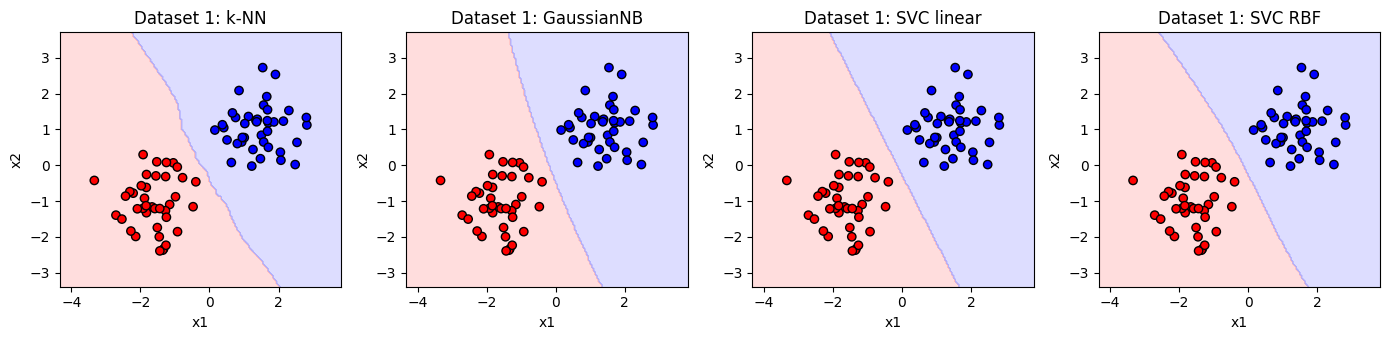

In [13]:
########## Dataset 1 ##########
knn = KNeighborsClassifier(n_neighbors=5)
nb = GaussianNB()
svm_linear = SVC(kernel="linear", C=1)
svm_rbf = SVC(kernel="rbf", C=1)

knn.fit(X1_train, y1_train)
nb.fit(X1_train, y1_train)
svm_linear.fit(X1_train, y1_train)
svm_rbf.fit(X1_train, y1_train)

plt.figure(figsize=(14, 3.5))

plt.subplot(1, 4, 1)
plot_boundary(knn, X_dataset1, y_dataset1, "Dataset 1: k-NN")

plt.subplot(1, 4, 2)
plot_boundary(nb, X_dataset1, y_dataset1, "Dataset 1: GaussianNB")

plt.subplot(1, 4, 3)
plot_boundary(svm_linear, X_dataset1, y_dataset1, "Dataset 1: SVC linear")

plt.subplot(1, 4, 4)
plot_boundary(svm_rbf, X_dataset1, y_dataset1, "Dataset 1: SVC RBF")

plt.tight_layout()
plt.show()

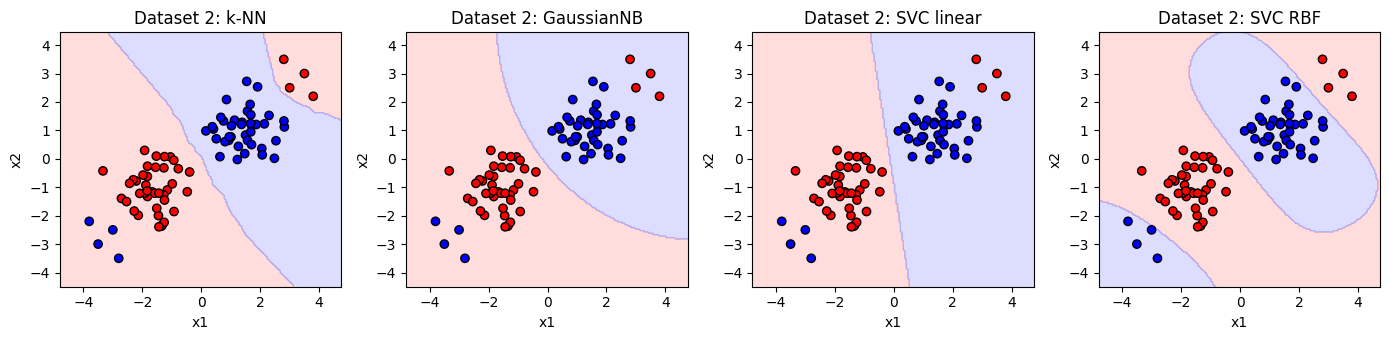

In [14]:
########## Dataset 2 ##########
knn = KNeighborsClassifier(n_neighbors=5)
nb = GaussianNB()
svm_linear = SVC(kernel="linear", C=1)
svm_rbf = SVC(kernel="rbf", C=1)

knn.fit(X2_train, y2_train)
nb.fit(X2_train, y2_train)
svm_linear.fit(X2_train, y2_train)
svm_rbf.fit(X2_train, y2_train)

plt.figure(figsize=(14, 3.5))

plt.subplot(1, 4, 1)
plot_boundary(knn, X_dataset2, y_dataset2, "Dataset 2: k-NN")

plt.subplot(1, 4, 2)
plot_boundary(nb, X_dataset2, y_dataset2, "Dataset 2: GaussianNB")

plt.subplot(1, 4, 3)
plot_boundary(svm_linear, X_dataset2, y_dataset2, "Dataset 2: SVC linear")

plt.subplot(1, 4, 4)
plot_boundary(svm_rbf, X_dataset2, y_dataset2, "Dataset 2: SVC RBF")

plt.tight_layout()
plt.show()

## B.I.7 — Similarities and dissimilarities

**Similarities**
- All are supervised classifiers.
- On Dataset 1 they all separate the two classes well.

**Dissimilarities**
- **k-NN**: looks at nearby points -> irregular boundary; sensitive to outliers if k is small.
- **GaussianNB**: assumes Gaussian features -> smooth boundary.
- **SVC linear**: straight line boundary.
- **SVC RBF**: curved boundary; more flexible, can bend around outliers.

The differences are much clearer on Dataset 2 because of the outliers.

## B.II.1 — Bias-variance with k-NN

We train k-NN with k = 1, 3, 5, 20, 50 and plot the decision boundaries.

Dataset 1  k=1: train=1.000  test=1.000
Dataset 1  k=3: train=1.000  test=1.000
Dataset 1  k=5: train=1.000  test=1.000
Dataset 1  k=20: train=1.000  test=1.000
Dataset 1  k=50: train=1.000  test=1.000


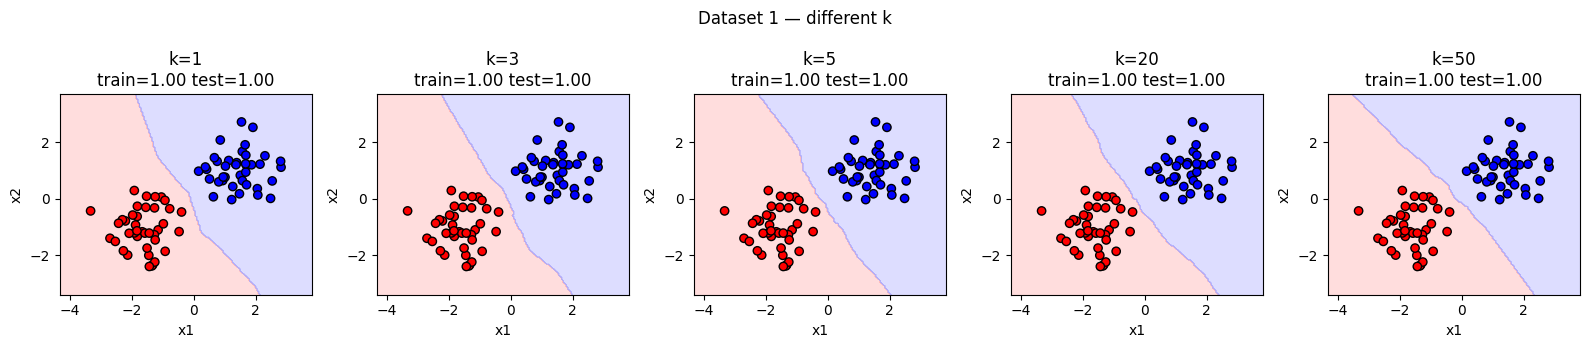

In [ ]:
########## Dataset 1 ##########
plt.figure(figsize=(16, 3.5))

for i, k in enumerate([1, 3, 5, 20, 50], start=1):
    k_use = min(k, len(y1_train))
    model = KNeighborsClassifier(n_neighbors=k_use)
    model.fit(X1_train, y1_train)

    train_acc = accuracy_score(y1_train, model.predict(X1_train))
    test_acc = accuracy_score(y1_test, model.predict(X1_test))

    print(f"Dataset 1  k={k_use}: train={train_acc:.3f}  test={test_acc:.3f}")

    plt.subplot(1, 5, i)
    plot_boundary(model, X_dataset1, y_dataset1,
                  f"k={k_use}\ntrain={train_acc:.2f} test={test_acc:.2f}")

plt.suptitle("Dataset 1 — different k")
plt.tight_layout()
plt.show()

Dataset 2  k=1: train=1.000  test=1.000
Dataset 2  k=3: train=1.000  test=0.963
Dataset 2  k=5: train=0.967  test=0.926
Dataset 2  k=20: train=0.918  test=0.889
Dataset 2  k=50: train=0.918  test=0.889


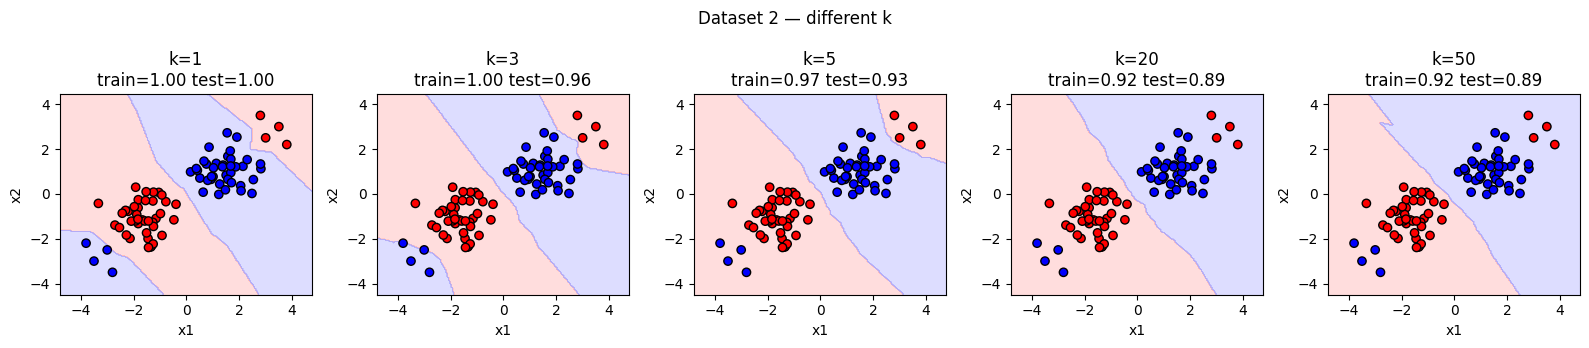

In [17]:
########## Dataset 2 ##########
plt.figure(figsize=(16, 3.5))

for i, k in enumerate([1, 3, 5, 20, 50], start=1):
    k_use = min(k, len(y2_train))
    model = KNeighborsClassifier(n_neighbors=k_use)
    model.fit(X2_train, y2_train)

    train_acc = accuracy_score(y2_train, model.predict(X2_train))
    test_acc = accuracy_score(y2_test, model.predict(X2_test))

    print(f"Dataset 2  k={k_use}: train={train_acc:.3f}  test={test_acc:.3f}")

    plt.subplot(1, 5, i)
    plot_boundary(model, X_dataset2, y_dataset2,
                  f"k={k_use}\ntrain={train_acc:.2f} test={test_acc:.2f}")

plt.suptitle("Dataset 2 — different k")
plt.tight_layout()
plt.show()

### Discussion B.II.1

When k increases, the decision boundary becomes smoother.

- Small k -> boundary follows the points closely (including outliers).
- Large k -> boundary becomes simpler and ignores local noise/outliers.

## B.II.2 — Bias-variance tradeoff

In machine learning, prediction error can be seen as:

**Error approx = Bias^2 + Variance + Noise**

- **Bias**: error from a model that is too simple (underfitting)
- **Variance**: error from a model that is too sensitive to the training data (overfitting)

### Link to k in k-NN

| k | Bias | Variance | What happens |
|---|------|----------|--------------|
| small (k=1, 3) | low | high | **overfitting** — boundary hugs every point |
| medium (k=5) | balanced | balanced | usually a good tradeoff |
| large (k=20, 50) | high | low | **underfitting** — boundary too smooth |

So:
- small k -> complex model -> low bias, high variance -> overfitting
- large k -> simple model -> high bias, low variance -> underfitting